In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [16]:
class RobotKesif:

    def __init__(self, size=10, num_obstacles=5):
        self.size = size
        self.num_obstacles = num_obstacles
        self.action_space = ["up", "down", "left", "right"]
        self.start_state = (0, 0)
        self.goal_state = (size - 1, size - 1)
        self.obstacles = self.generate_obstacles()
        self.current_state = self.start_state

    def generate_obstacles(self):
        obstacles = set()
        while len(obstacles) < self.num_obstacles:
            obstacle = (
                random.randint(0, self.size - 1),
                random.randint(0, self.size - 1),
            )
            if obstacle != self.start_state and obstacle != self.goal_state:
                obstacles.add(obstacle)
        return obstacles

    def reset(self):
        self.current_state = self.start_state
        return self.current_state

    def step(self, action):
        row, col = self.current_state
        if action == "up":
            next_state = (row - 1, col)
        elif action == "down":
            next_state = (row + 1, col)
        elif action == "left":
            next_state = (row, col - 1)
        elif action == "right":
            next_state = (row, col + 1)
        else:
            raise ValueError("Invalid action")
        if not (0 <= next_state[0] < self.size and 0 <= next_state[1] < self.size):
            next_state = self.current_state
            reward = -5
            done = False
        elif next_state in self.obstacles:
            reward = -10
            done = True
        elif next_state == self.goal_state:
            reward = 10
            done = True
        else:
            reward = -1
            done = False
        self.current_state = next_state
        return next_state, reward, done

In [17]:
class QLearningAgent:
    def __init__(
        self,
        env,
        alpha=0.1,
        gamma=0.9,
        epsilon=1.0,
        epsilon_decay=0.995,
        epsilon_min=0.01,
    ):
        self.env = env
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.q_table = np.zeros((env.size, env.size, len(env.action_space)))

    def choose_action(self, state):
        if random.random() < self.epsilon:
            return random.choice(self.env.action_space)
        row, col = state
        action_index = np.argmax(self.q_table[row, col])
        return self.env.action_space[action_index]

    def update_q_value(self, state, action, reward, next_state, done):
        row, col = state
        action_index = self.env.action_space.index(action)
        current_q = self.q_table[row, col, action_index]
        if done:
            target = reward
        else:
            next_row, next_col = next_state
            max_next_q = np.max(self.q_table[next_row, next_col])
            target = reward + self.gamma * max_next_q
        self.q_table[row, col, action_index] += self.alpha * (target - current_q)

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

In [ ]:
def train_agent(env, agent, episodes=1000, max_steps=200):

    rewards = []
    successes = []

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        done = False
        for step in range(max_steps):
            action = agent.choose_action(state)
            next_state, reward, done = env.step(action)
            agent.update_q_value(state, action, reward, next_state, done)
            state = next_state
            total_reward += reward
            if done:
                break
        agent.decay_epsilon()
        rewards.append(total_reward)
        if state == env.goal_state:
            successes.append(1)
        else:
            successes.append(0)

    return rewards, successes

In [20]:
env = RobotKesif(size=10, num_obstacles=5)
agent = QLearningAgent(env)
rewards, successes = train_agent(env, agent, episodes=1000)

print("Training completed.")
print("Final epsilon:", agent.epsilon)

Training completed.
Final epsilon: 0.01


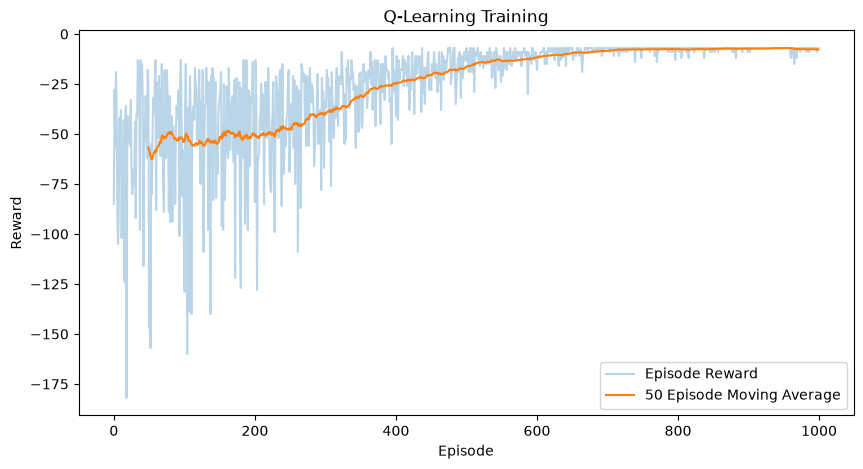

In [21]:
window = 50
moving_average = np.convolve(rewards, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 5))
plt.plot(rewards, alpha=0.3, label="Episode Reward")
plt.plot(
    range(window - 1, len(rewards)), moving_average, label="50 Episode Moving Average"
)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Q-Learning Training")
plt.legend()
plt.show()

In [22]:
success_rate = np.mean(successes) * 100

print(f"Success rate: {success_rate:.2f}%")
print(f"Final epsilon: {agent.epsilon:.4f}")

Success rate: 73.60%
Final epsilon: 0.0100


In [24]:
def test_agent(env, agent, max_steps=100):

    old_epsilon = agent.epsilon
    agent.epsilon = 0
    state = env.reset()
    path = [state]
    total_reward = 0

    for _ in range(max_steps):
        action = agent.choose_action(state)
        next_state, reward, done = env.step(action)
        path.append(next_state)
        total_reward += reward
        state = next_state
        if done:
            break
    agent.epsilon = old_epsilon
    return path, total_reward

In [25]:
path, total_reward = test_agent(env, agent)

print("Path:")
print(path)

print("\nTotal reward:")
print(total_reward)

print("\nReached goal:")
print(path[-1] == env.goal_state)

Path:
[(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (4, 5), (4, 6), (4, 7), (5, 7), (6, 7), (7, 7), (8, 7), (9, 7), (9, 8), (9, 9)]

Total reward:
-7

Reached goal:
True


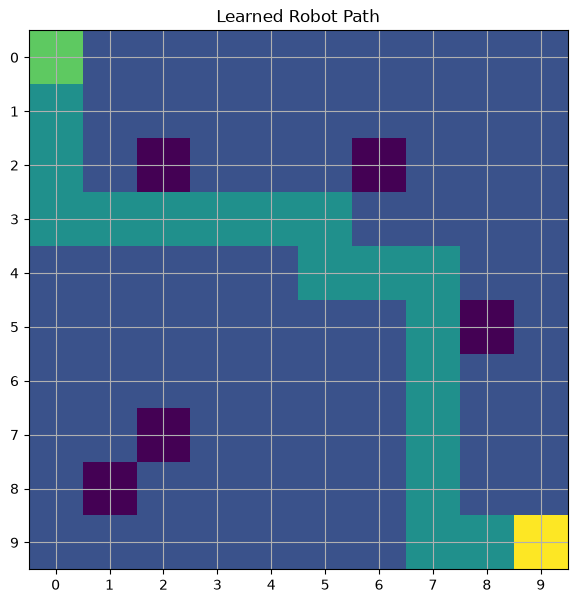

In [26]:
def visualize(env, path):

    grid = np.zeros((env.size, env.size))

    for row, col in env.obstacles:
        grid[row, col] = -1

    for row, col in path:
        grid[row, col] = 1

    start_row, start_col = env.start_state
    grid[start_row, start_col] = 2

    goal_row, goal_col = env.goal_state
    grid[goal_row, goal_col] = 3

    plt.figure(figsize=(7, 7))
    plt.imshow(grid)
    plt.xticks(range(env.size))
    plt.yticks(range(env.size))
    plt.grid(True)
    plt.title("Learned Robot Path")
    plt.show()


visualize(env, path)